In [2]:
import pandas as pd

In [4]:
import os

files = [
    "X_train_processed.csv",
    "X_test_processed.csv",
    "y_train.csv",
    "y_test.csv",
    "feature_names.csv"
]

for file in files:
    print(file, "→", os.path.exists(file))

X_train_processed.csv → True
X_test_processed.csv → True
y_train.csv → True
y_test.csv → True
feature_names.csv → True


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
pd.set_option('display.max_columns',None)

In [12]:
X_train = pd.read_csv(r"../DATA/FeatureSelectionData/X_train_processed.csv")
X_test = pd.read_csv(r"../DATA/FeatureSelectionData/X_test_processed.csv")

y_train = pd.read_csv(r"../DATA/FeatureSelectionData/y_train.csv").squeeze()
y_test = pd.read_csv(r"../DATA/FeatureSelectionData/y_test.csv").squeeze()

In [14]:
X_train.head()

,categorical__race_AfricanAmerican,categorical__race_Asian,categorical__race_Caucasian,categorical__race_Other,categorical__gender_Female,categorical__gender_Male,categorical__medical_specialty_AllergyandImmunology,categorical__medical_specialty_Anesthesiology,categorical__medical_specialty_Anesthesiology-Pediatric,categorical__medical_specialty_Cardiology,categorical__medical_specialty_Cardiology-Pediatric,categorical__medical_specialty_DCPTEAM,categorical__medical_specialty_Dentistry,categorical__medical_specialty_Dermatology,categorical__medical_specialty_Emergency/Trauma,categorical__medical_specialty_Endocrinology,categorical__medical_specialty_Endocrinology-Metabolism,categorical__medical_specialty_Family/GeneralPractice,categorical__medical_specialty_Gastroenterology,categorical__medical_specialty_Gynecology,categorical__medical_specialty_Hematology,categorical__medical_specialty_Hematology/Oncology,categorical__medical_specialty_Hospitalist,categorical__medical_specialty_InfectiousDiseases,categorical__medical_specialty_InternalMedicine,categorical__medical_specialty_Nephrology,categorical__medical_specialty_Neurology,categorical__medical_specialty_Obsterics&Gynecology-GynecologicOnco,categorical__medical_specialty_Obstetrics,categorical__medical_specialty_ObstetricsandGynecology,categorical__medical_specialty_Oncology,categorical__medical_specialty_Ophthalmology,categorical__medical_specialty_Orthopedics,categorical__medical_specialty_Orthopedics-Reconstructive,categorical__medical_specialty_Osteopath,categorical__medical_specialty_Otolaryngology,categorical__medical_specialty_OutreachServices,categorical__medical_specialty_Pathology,categorical__medical_specialty_Pediatrics,categorical__medical_specialty_Pediatrics-AllergyandImmunology,categorical__medical_specialty_Pediatrics-CriticalCare,categorical__medical_specialty_Pediatrics-EmergencyMedicine,categorical__medical_specialty_Pediatrics-Endocrinology,categorical__medical_specialty_Pediatrics-Hematology-Oncology,categorical__medical_specialty_Pediatrics-InfectiousDiseases,categorical__medical_specialty_Pediatrics-Neurology,categorical__medical_specialty_Pediatrics-Pulmonology,categorical__medical_specialty_Perinatology,categorical__medical_specialty_PhysicalMedicineandRehabilitation,categorical__medical_specialty_PhysicianNotFound,categorical__medical_specialty_Podiatry,categorical__medical_specialty_Proctology,categorical__medical_specialty_Psychiatry,categorical__medical_specialty_Psychiatry-Child/Adolescent,categorical__medical_specialty_Psychology,categorical__medical_specialty_Pulmonology,categorical__medical_specialty_Radiologist,categorical__medical_specialty_Radiology,categorical__medical_specialty_Resident,categorical__medical_specialty_Rheumatology,categorical__medical_specialty_SportsMedicine,categorical__medical_specialty_Surgeon,categorical__medical_specialty_Surgery-Cardiovascular,categorical__medical_specialty_Surgery-Cardiovascular/Thoracic,categorical__medical_specialty_Surgery-Colon&Rectal,categorical__medical_specialty_Surgery-General,categorical__medical_specialty_Surgery-Maxillofacial,categorical__medical_specialty_Surgery-Neuro,categorical__medical_specialty_Surgery-Pediatric,categorical__medical_specialty_Surgery-Plastic,categorical__medical_specialty_Surgery-PlasticwithinHeadandNeck,categorical__medical_specialty_Surgery-Thoracic,categorical__medical_specialty_Surgery-Vascular,categorical__medical_specialty_SurgicalSpecialty,categorical__medical_specialty_Unknown,categorical__medical_specialty_Urology,categorical__metformin_Down,categorical__metformin_No,categorical__metformin_Steady,categorical__metformin_Up,categorical__repaglinide_Down,categorical__repaglinide_No,categorical__repaglinide_Steady,categorical__repaglinide_Up,categorical__nateglinide_Down,categorical__nateglinide_No,categorical__nateglinide_Steady,categorical__nateglinide_Up,categorical__chlorpropamide_Down,categorical__chlorpropamide_No,categorical__chlorpropamide_Steady,cat

###  Find constant features

In [15]:
constant_features = [
    column
    for column in X_train.columns
    if X_train[column].nunique() <= 1
]

print("Number of constant features:", len(constant_features))
print("Constant features:", constant_features)

Number of constant features: 5
Constant features: ['categorical__examide_No', 'categorical__citoglipton_No', 'categorical__metformin-rosiglitazone_No', 'categorical__metformin-pioglitazone_No', 'remainder__num_diagnoses_present']


In [16]:
if constant_features:
    X_train = X_train.drop(columns=constant_features)
    X_test = X_test.drop(columns=constant_features)

print("New training shape:", X_train.shape)
print("New testing shape:", X_test.shape)

New training shape: (75028, 251)
New testing shape: (18758, 251)


### Calculate the correlation matrix

In [17]:
correlation_matrix = X_train.corr().abs()

In [18]:
high_correlations = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        
        if correlation_matrix.iloc[i, j] > 0.90:
            
            high_correlations.append(
                (
                    correlation_matrix.columns[i],
                    correlation_matrix.columns[j],
                    correlation_matrix.iloc[i, j]
                )
            )

In [19]:
print("Highly correlated feature pairs:")

for feature1, feature2, correlation in high_correlations:
    print(
        f"{feature1} <-> {feature2} : {correlation:.3f}"
    )

Highly correlated feature pairs:
categorical__race_Caucasian <-> categorical__race_AfricanAmerican : 0.942
categorical__gender_Male <-> categorical__gender_Female : 1.000
categorical__metformin_Steady <-> categorical__metformin_No : 0.949
categorical__repaglinide_Steady <-> categorical__repaglinide_No : 0.951
categorical__nateglinide_Steady <-> categorical__nateglinide_No : 0.982
categorical__chlorpropamide_Steady <-> categorical__chlorpropamide_No : 0.957
categorical__glimepiride_Steady <-> categorical__glimepiride_No : 0.944
categorical__acetohexamide_Steady <-> categorical__acetohexamide_No : 1.000
categorical__glipizide_Steady <-> categorical__glipizide_No : 0.940
categorical__glyburide_Steady <-> categorical__glyburide_No : 0.927
categorical__tolbutamide_Steady <-> categorical__tolbutamide_No : 1.000
categorical__pioglitazone_Steady <-> categorical__pioglitazone_No : 0.974
categorical__rosiglitazone_Steady <-> categorical__rosiglitazone_No : 0.978
categorical__acarbose_Steady <-> 

### Get the features involved

In [20]:
correlated_features = set()

for feature1, feature2, correlation in high_correlations:
    correlated_features.add(feature1)
    correlated_features.add(feature2)

print("Number of features involved:",
      len(correlated_features))

print("\nFeatures:")
print(correlated_features)

Number of features involved: 98

Features:
{'categorical__medical_specialty_Otolaryngology', 'categorical__diabetesMed_No', 'categorical__medical_specialty_grouped_Neurology', 'categorical__repaglinide_Steady', 'categorical__medical_specialty_Neurology', 'remainder__num_medications_changed', 'categorical__medical_specialty_grouped_Emergency/Trauma', 'categorical__race_Caucasian', 'categorical__medical_specialty_Surgery-Vascular', 'categorical__medical_specialty_grouped_Surgery-Thoracic', 'categorical__gender_Male', 'categorical__glyburide-metformin_No', 'categorical__medical_specialty_Surgery-Thoracic', 'categorical__change_No', 'categorical__medical_specialty_Nephrology', 'categorical__tolazamide_Steady', 'categorical__medical_specialty_PhysicalMedicineandRehabilitation', 'categorical__acetohexamide_Steady', 'categorical__medical_specialty_Gastroenterology', 'categorical__medical_specialty_Oncology', 'categorical__troglitazone_No', 'categorical__medical_specialty_Surgery-General', 'ca

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_subset = X_train[
    list(correlated_features)
].corr()

In [33]:
plt.figure(figsize=(100,100))
sns.heatmap(correlation_subset,annot=True,fmt='.2f')

<Axes: >

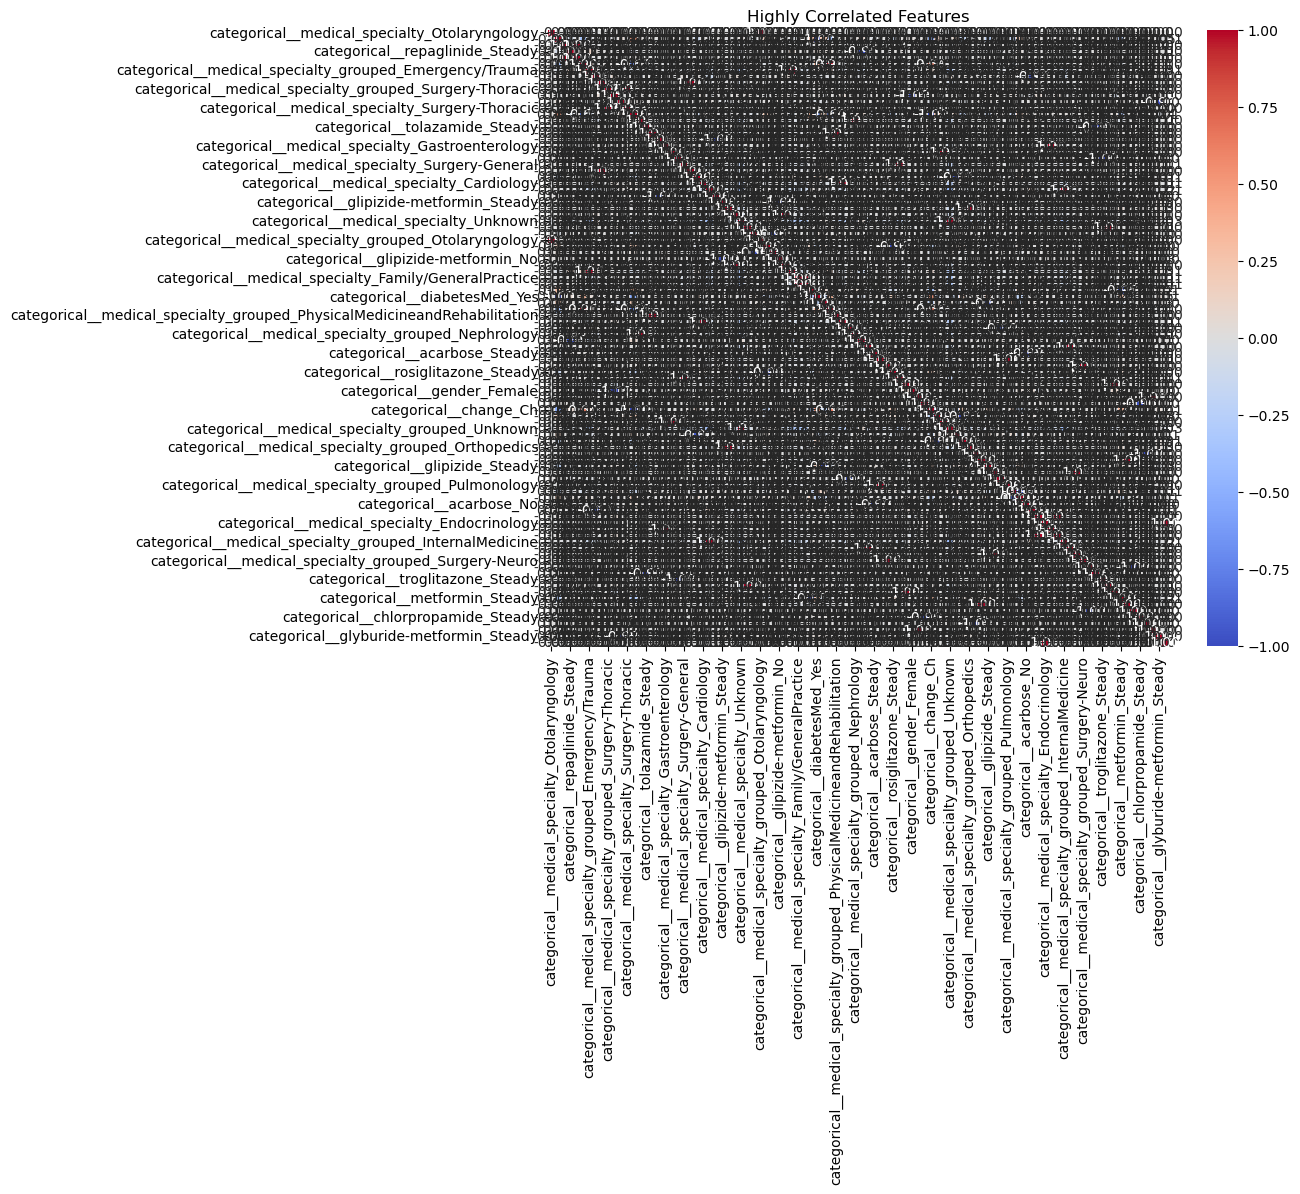

In [34]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_subset,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Highly Correlated Features")
plt.show()

### Identify redundant features

In [35]:
for feature1, feature2, correlation in high_correlations:
    print(f"{feature1} <-> {feature2} : {correlation:.3f}")

categorical__race_Caucasian <-> categorical__race_AfricanAmerican : 0.942
categorical__gender_Male <-> categorical__gender_Female : 1.000
categorical__metformin_Steady <-> categorical__metformin_No : 0.949
categorical__repaglinide_Steady <-> categorical__repaglinide_No : 0.951
categorical__nateglinide_Steady <-> categorical__nateglinide_No : 0.982
categorical__chlorpropamide_Steady <-> categorical__chlorpropamide_No : 0.957
categorical__glimepiride_Steady <-> categorical__glimepiride_No : 0.944
categorical__acetohexamide_Steady <-> categorical__acetohexamide_No : 1.000
categorical__glipizide_Steady <-> categorical__glipizide_No : 0.940
categorical__glyburide_Steady <-> categorical__glyburide_No : 0.927
categorical__tolbutamide_Steady <-> categorical__tolbutamide_No : 1.000
categorical__pioglitazone_Steady <-> categorical__pioglitazone_No : 0.974
categorical__rosiglitazone_Steady <-> categorical__rosiglitazone_No : 0.978
categorical__acarbose_Steady <-> categorical__acarbose_No : 0.975


In [36]:
print("Number of highly correlated pairs:",
      len(high_correlations))

Number of highly correlated pairs: 49


### Model-Based Feature Importance

In [37]:
from sklearn.ensemble import RandomForestClassifier

In [38]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [39]:
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [40]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
})

In [41]:
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(20))

                                        Feature  Importance
237               remainder__num_lab_procedures    0.065210
239                  remainder__num_medications    0.059400
236                 remainder__time_in_hospital    0.038262
234         remainder__discharge_disposition_id    0.033569
243                 remainder__number_diagnoses    0.032010
238                   remainder__num_procedures    0.030873
232                              remainder__age    0.030106
246            remainder__total_previous_visits    0.027344
242                 remainder__number_inpatient    0.022863
233                remainder__admission_type_id    0.022144
245  remainder__num_unique_diagnosis_categories    0.020397
235              remainder__admission_source_id    0.018795
247                remainder__total_medications    0.014346
244                           remainder__weight    0.014188
181    categorical__diag_3_category_Circulatory    0.013294
185      categorical__diag_3_category_En

### Visualize Feature Importance

In [42]:
top_features = feature_importance.head(20)

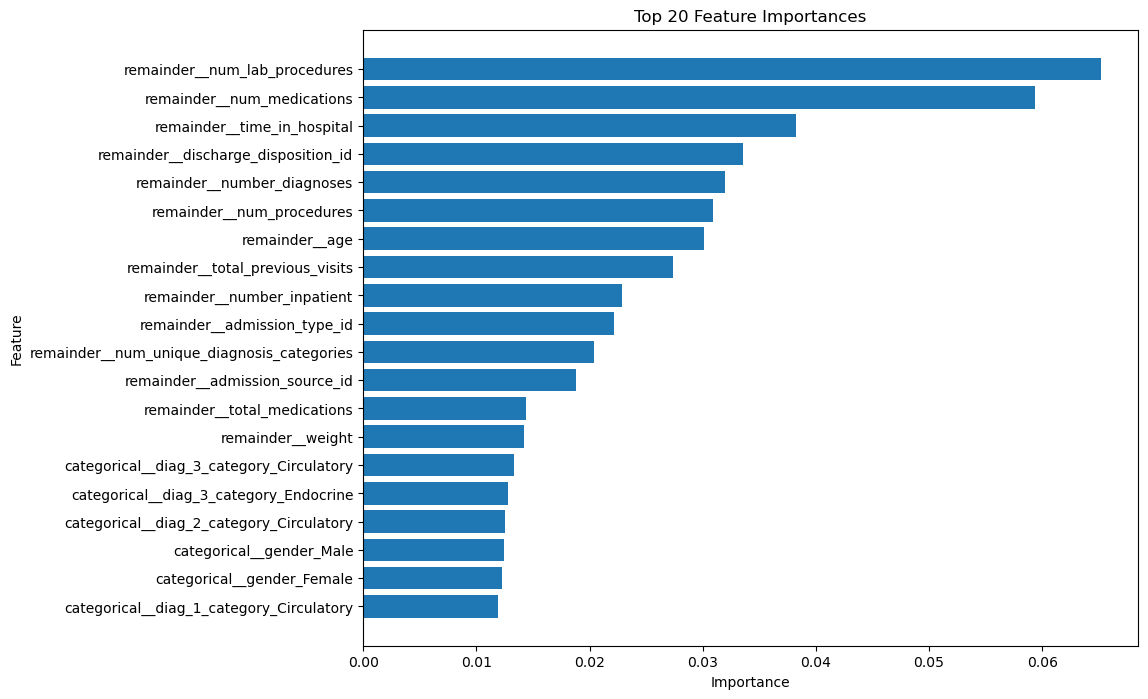

In [43]:
plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 Feature Importances")

plt.gca().invert_yaxis()

plt.show()

In [46]:
print(
    top_features.to_string(index=False)
)


                                   Feature  Importance
             remainder__num_lab_procedures    0.065210
                remainder__num_medications    0.059400
               remainder__time_in_hospital    0.038262
       remainder__discharge_disposition_id    0.033569
               remainder__number_diagnoses    0.032010
                 remainder__num_procedures    0.030873
                            remainder__age    0.030106
          remainder__total_previous_visits    0.027344
               remainder__number_inpatient    0.022863
              remainder__admission_type_id    0.022144
remainder__num_unique_diagnosis_categories    0.020397
            remainder__admission_source_id    0.018795
              remainder__total_medications    0.014346
                         remainder__weight    0.014188
  categorical__diag_3_category_Circulatory    0.013294
    categorical__diag_3_category_Endocrine    0.012799
  categorical__diag_2_category_Circulatory    0.012528
          

### Select important features

In [50]:
print(feature_importance["Importance"].describe())

count    2.510000e+02
mean     3.984064e-03
std      7.990187e-03
min      1.151138e-07
25%      8.366606e-05
50%      9.418549e-04
75%      4.673769e-03
max      6.521025e-02
Name: Importance, dtype: float64


### Choose a threshold

In [51]:
importance_threshold = 0.001

In [52]:
selected_features = feature_importance[
    feature_importance["Importance"] >= importance_threshold
]["Feature"].tolist()

In [53]:
print("Original number of features:",
      X_train.shape[1])

print("Selected number of features:",
      len(selected_features))

Original number of features: 251
Selected number of features: 123


In [54]:
print("Selected features:")

for feature in selected_features:
    print(feature)

Selected features:
remainder__num_lab_procedures
remainder__num_medications
remainder__time_in_hospital
remainder__discharge_disposition_id
remainder__number_diagnoses
remainder__num_procedures
remainder__age
remainder__total_previous_visits
remainder__number_inpatient
remainder__admission_type_id
remainder__num_unique_diagnosis_categories
remainder__admission_source_id
remainder__total_medications
remainder__weight
categorical__diag_3_category_Circulatory
categorical__diag_3_category_Endocrine
categorical__diag_2_category_Circulatory
categorical__gender_Male
categorical__gender_Female
categorical__diag_1_category_Circulatory
remainder__number_outpatient
remainder__has_previous_visits
categorical__diag_2_category_Endocrine
remainder__number_emergency
categorical__age_group_Middle_Aged
categorical__race_Caucasian
categorical__stay_category_Medium
categorical__age_group_Senior
categorical__race_AfricanAmerican
categorical__medical_specialty_Unknown
categorical__medical_specialty_grouped_

In [55]:
print("Original number of features:", X_train.shape[1])
print("Selected number of features:", len(selected_features))

Original number of features: 251
Selected number of features: 123


### Create the selected feature datasets

In [57]:
X_train_selected = X_train[selected_features]

In [58]:
X_test_selected = X_test[selected_features]

In [59]:
print("Original X_train shape:", X_train.shape)
print("Selected X_train shape:", X_train_selected.shape)

print("\nOriginal X_test shape:", X_test.shape)
print("Selected X_test shape:", X_test_selected.shape)

Original X_train shape: (75028, 251)
Selected X_train shape: (75028, 123)

Original X_test shape: (18758, 251)
Selected X_test shape: (18758, 123)


In [60]:
print("Selected feature columns:")
print(X_train_selected.columns.tolist())

Selected feature columns:
['remainder__num_lab_procedures', 'remainder__num_medications', 'remainder__time_in_hospital', 'remainder__discharge_disposition_id', 'remainder__number_diagnoses', 'remainder__num_procedures', 'remainder__age', 'remainder__total_previous_visits', 'remainder__number_inpatient', 'remainder__admission_type_id', 'remainder__num_unique_diagnosis_categories', 'remainder__admission_source_id', 'remainder__total_medications', 'remainder__weight', 'categorical__diag_3_category_Circulatory', 'categorical__diag_3_category_Endocrine', 'categorical__diag_2_category_Circulatory', 'categorical__gender_Male', 'categorical__gender_Female', 'categorical__diag_1_category_Circulatory', 'remainder__number_outpatient', 'remainder__has_previous_visits', 'categorical__diag_2_category_Endocrine', 'remainder__number_emergency', 'categorical__age_group_Middle_Aged', 'categorical__race_Caucasian', 'categorical__stay_category_Medium', 'categorical__age_group_Senior', 'categorical__race_A

### Save the selected features

In [61]:
X_train_selected.to_csv(
    "X_train_selected.csv",
    index=False
)

In [62]:
X_test_selected.to_csv(
    "X_test_selected.csv",
    index=False
)

In [63]:
y_train.to_csv(
    "y_train_selected.csv",
    index=False
)

y_test.to_csv(
    "y_test_selected.csv",
    index=False
)

### Save the selected feature names

In [64]:
pd.Series(selected_features).to_csv(
    "selected_features.csv",
    index=False
)

In [65]:
import os

files = [
    "X_train_selected.csv",
    "X_test_selected.csv",
    "y_train_selected.csv",
    "y_test_selected.csv",
    "selected_features.csv"
]

for file in files:
    print(file, "→", os.path.exists(file))

X_train_selected.csv → True
X_test_selected.csv → True
y_train_selected.csv → True
y_test_selected.csv → True
selected_features.csv → True
